# Actividad — Comparación de métodos de selección de variables · SOLUCIONARIO
**Aprendizaje Supervisado · Unidad 3 · Ingeniería y selección de variables**

**Qué haremos.** En la presentación vimos cómo *crear* variables y tres familias de métodos para *seleccionarlas*
(filtro, envoltura e integrado). Hoy los aplicarás al conjunto de **cáncer de mama de Wisconsin** (569 pacientes, 30 mediciones
de núcleos celulares, diagnóstico *maligno* o *benigno*) y compararás **con el mismo protocolo**: ¿cuántas variables bastan?
¿qué método elige mejor? ¿las listas de variables son estables? ¿qué pasa si seleccionas mal?

| Parte | Pregunta que responde | Tema de la presentación |
|---|---|---|
| 0–1 | ¿Qué datos tenemos, cuál es la línea base y cuánto dañan las variables inútiles? | Introducción |
| 2 | ¿Ayudan las variables del dominio y los polinomios? | A1–A8 |
| 3 | ¿Qué hacen la varianza, la correlación y la información mutua? | C1–C9 |
| 4 | ¿Qué variables sobreviven a la eliminación recursiva (RFE)? | D1–D5 |
| 5 | ¿Qué variables conserva Lasso? | E1–E5 |
| 6 | ¿Cómo se comparan los cuatro métodos, con la selección **dentro** del pipeline? | F1, F4 |
| 7 | ¿Eligen siempre las mismas variables? | F2 |
| 8 | ¿Cómo se ve (y se evita) una fuga de datos al seleccionar? | C9 |
| 9 | Recomendación final | Receta de siete pasos |

**Tiempo estimado:** 60–75 minutos de trabajo individual.

**Entregable:** este notebook ejecutado (con tus respuestas en las celdas ✏️) y el archivo `entregable_unidad3.csv`
con la tabla *método · k · exactitud de validación · sensibilidad · variables elegidas · comentario* de la Parte 6.

**Cómo trabajar.** Ejecuta las celdas en orden. Donde dice ✏️ hay una línea de código por completar o una pregunta;
escribe tus respuestas en la celda de texto que sigue a la pregunta, bajo «**Respuesta:**».
Todas las cifras de exactitud vienen de **validación cruzada con 5 particiones repetida 3 veces** sobre el conjunto de entrenamiento;
el conjunto de prueba se usa **una sola vez**, al final de la Parte 6.

> ⚠️ Es un conjunto médico: una variable que «ayuda» al modelo no es necesariamente una variable que un experto aceptaría.
> Por eso, además de la exactitud, medimos la **sensibilidad**: de los casos *malignos*, ¿qué fracción detecta el modelo?

> 🔑 **Versión con respuestas (para el profesor).** Las respuestas aparecen en recuadros ✅ después de cada pregunta; las celdas de código están completas y ejecutadas. Las cifras provienen de una ejecución con `random_state` fijos; pueden variar ligeramente con otras versiones de scikit-learn.

In [1]:
import warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from functools import partial
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_validate, cross_val_score, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import (VarianceThreshold, SelectKBest, f_classif, mutual_info_classif,
                                       RFE, RFECV, SelectFromModel)
from sklearn.metrics import make_scorer, recall_score, accuracy_score, confusion_matrix

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 140)

# La información mutua se estima con vecinos y usa un poco de azar: fijamos la semilla para que los resultados se repitan
mi_clasif = partial(mutual_info_classif, random_state=0)

## Parte 0 — Los datos

El conjunto viene incluido en scikit-learn. Cada paciente tiene **10 medidas** del núcleo de las células de una biopsia
(radio, textura, perímetro, área, suavidad, compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal),
cada una resumida de **tres formas**: media (`mean`), error estándar (`error`) y peor valor (`worst`). En total, 30 variables.
En `y`, **0 = maligno** y **1 = benigno**.

In [2]:
bc = load_breast_cancer(as_frame=True)
X, y = bc.data, bc.target          # y: 0 = maligno, 1 = benigno

print(X.shape)
print(y.map({0: "maligno", 1: "benigno"}).value_counts().to_string())
X.iloc[:, :6].head()

(569, 30)
target
benigno    357
maligno    212


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
0,17.99,10.38,122.80,1001.0,0.11840,0.27760
1,20.57,17.77,132.90,1326.0,0.08474,0.07864
2,19.69,21.25,130.00,1203.0,0.10960,0.15990
3,11.42,20.38,77.58,386.1,0.14250,0.28390
4,20.29,14.34,135.10,1297.0,0.10030,0.13280


## Parte 1 — División, línea base y el daño de las variables inútiles

Regla de la receta: lo primero es separar el conjunto de prueba, **estratificando** por el diagnóstico para conservar la proporción de casos malignos.
Después medimos una **línea base**: regresión logística con las 30 variables estandarizadas.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Entrenamiento:", X_train.shape, " Prueba:", X_test.shape)
print(f"Proporción de malignos -> entrenamiento: {100 * (y_train == 0).mean():.1f} %   prueba: {100 * (y_test == 0).mean():.1f} %")

# Protocolo de validación que usaremos SIEMPRE (el conjunto de prueba no se toca hasta el final de la Parte 6)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
sens_maligno = make_scorer(recall_score, pos_label=0)      # de los casos malignos, ¿cuántos detecta?


def evalua(pipe, Xd=None):
    # Devuelve (exactitud, sensibilidad a malignos), promedios de la validación cruzada, sobre el conjunto de entrenamiento
    Xd = X_train if Xd is None else Xd
    r = cross_validate(pipe, Xd, y_train, cv=cv, n_jobs=-1,
                       scoring={"exactitud": "accuracy", "sens": sens_maligno})
    return r["test_exactitud"].mean(), r["test_sens"].mean()


base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
acc0, sens0 = evalua(base)
print(f"Línea base (30 variables): exactitud = {acc0:.3f}   sensibilidad a malignos = {sens0:.3f}")

Entrenamiento: (455, 30)  Prueba: (114, 30)
Proporción de malignos -> entrenamiento: 37.4 %   prueba: 36.8 %


Línea base (30 variables): exactitud = 0.978   sensibilidad a malignos = 0.961


✏️ **Pregunta 1.1.** ¿Por qué estandarizamos antes de la regresión logística y por qué lo hacemos *dentro* del `Pipeline`?
En un diagnóstico médico, ¿por qué no basta con la exactitud? ¿Qué error es más grave: un maligno clasificado como benigno o al revés?

> ✅ **Respuesta (solucionario)**
>
> **Por qué estandarizar:** las variables están en escalas muy distintas (el área mide cientos o miles; la suavidad, décimas). La regresión logística penaliza los coeficientes (L2, `C=1`) y la penalización afecta distinto según la escala, y además converge mejor con variables comparables. Dentro del `Pipeline`, la media y la desviación estándar se calculan **solo con las filas de entrenamiento de cada partición**, así que no hay fuga.
>
> **Por qué no basta la exactitud:** 63 % de los pacientes son benignos; un modelo que dijera «benigno» siempre tendría 0.63 de exactitud sin detectar un solo caso. La línea base acierta 0.978, pero su **sensibilidad a malignos es 0.961**: de cada 100 casos malignos, casi 4 se le escapan.
>
> **Error más grave:** clasificar un **maligno como benigno** (falso negativo): retrasa el tratamiento. Un benigno clasificado como maligno (falsa alarma) genera una biopsia o estudios adicionales y angustia, pero se corrige. Por eso vigilamos la sensibilidad.

In [4]:
# ¿Cuánto daña agregar columnas que no significan nada? Añadimos ruido gaussiano puro y medimos de nuevo.
rng = np.random.default_rng(0)
filas = []
for n_ruido in [0, 50, 200]:
    Xr = X_train.copy()
    for j in range(n_ruido):
        Xr[f"ruido_{j}"] = rng.normal(size=len(Xr))
    for nombre, modelo in [("Regresión logística", make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))),
                           ("KNN (k=5)", make_pipeline(StandardScaler(), KNeighborsClassifier(5)))]:
        filas.append({"columnas de ruido": n_ruido, "modelo": nombre, "exactitud": evalua(modelo, Xr)[0]})
print(pd.DataFrame(filas).pivot(index="columnas de ruido", columns="modelo", values="exactitud").round(3))

modelo             KNN (k=5)  Regresión logística
columnas de ruido                                
0                      0.968                0.978
50                     0.933                0.964
200                    0.906                0.934


✏️ **Pregunta 1.2.** ¿Qué modelo sufre más con las columnas de ruido y por qué? ¿Qué te dice esto sobre la utilidad de **seleccionar** variables?

> ✅ **Respuesta (solucionario)**
>
> **KNN sufre más:** su exactitud baja de 0.968 a 0.906 con 200 columnas de ruido (−6.2 puntos), contra 0.978 a 0.934 en la regresión logística (−4.4 puntos). Con 50 columnas: 0.933 y 0.964.
>
> **Por qué:** KNN decide con distancias; ya estandarizadas, cada columna de ruido pesa igual que una columna informativa, y con 200 de ellas los «vecinos más cercanos» son casi al azar. La regresión logística puede dar coeficientes pequeños a las columnas inútiles, pero con 455 filas y 230 columnas empieza a ajustar ruido.
>
> **Conclusión:** cada variable inútil cuesta exactitud (y tiempo y claridad). Seleccionar variables reduce el ruido, el riesgo de sobreajuste y el costo, y da un modelo más fácil de explicar.

## Parte 2 — Crear variables del dominio y polinomios  *(presentación A1–A8)*

Un patólogo no mira solo el tamaño del núcleo: mira qué tan **irregular** es. Un círculo perfecto cumple $P^2=4\pi A$ (perímetro al cuadrado entre área),
y cualquier irregularidad aumenta esa razón. Definimos la **circularidad** $P^2/(4\pi A)$ (vale 1 para un círculo y crece con las irregularidades)
y varias razones «peor valor entre valor medio». Las envolvemos en un `FunctionTransformer` para que sean un paso más del pipeline.

In [5]:
def agrega_dominio(d):
    d = d.copy()
    d["circularidad media"] = d["mean perimeter"] ** 2 / (4 * np.pi * d["mean area"])
    d["circularidad peor"] = d["worst perimeter"] ** 2 / (4 * np.pi * d["worst area"])
    d["razon radio peor/medio"] = d["worst radius"] / d["mean radius"]
    d["razon textura peor/medio"] = d["worst texture"] / d["mean texture"]
    return d


nuevas = agrega_dominio(X_train).iloc[:, 30:]
print(nuevas.describe().loc[["mean", "min", "max"]].round(2).T)
print("\nCorrelación con el diagnóstico (|r|):")
print(nuevas.corrwith(y_train).abs().round(3).to_string())

                          mean   min   max
circularidad media        1.09  1.02  1.32
circularidad peor         1.13  1.01  1.52
razon radio peor/medio    1.14  1.00  1.57
razon textura peor/medio  1.33  1.00  2.07

Correlación con el diagnóstico (|r|):
circularidad media          0.534
circularidad peor           0.384
razon radio peor/medio      0.644
razon textura peor/medio    0.162


In [6]:
con_dominio = make_pipeline(FunctionTransformer(agrega_dominio), StandardScaler(), LogisticRegression(max_iter=3000))
acc1, sens1 = evalua(con_dominio)
print(f"30 variables originales     : exactitud = {acc0:.3f}   sensibilidad = {sens0:.3f}")
print(f"30 + 4 variables de dominio : exactitud = {acc1:.3f}   sensibilidad = {sens1:.3f}")

30 variables originales     : exactitud = 0.978   sensibilidad = 0.961
30 + 4 variables de dominio : exactitud = 0.978   sensibilidad = 0.965


✏️ **Pregunta 2.1.** ¿Mejoraron las variables de dominio la exactitud? ¿Qué te dice la correlación de cada una con el diagnóstico?
¿Por qué una variable nueva puede no ayudar cuando el modelo ya tiene 30 variables correlacionadas entre sí?

> ✅ **Respuesta (solucionario)**
>
> **No mejoraron:** la exactitud es la misma (0.978 con ambos conjuntos) y la sensibilidad pasa de 0.961 a 0.965, diferencia de menos de un caso, dentro del ruido de la validación.
>
> **Correlaciones:** la razón del radio (peor/medio) tiene |r| = 0.64 y la circularidad media 0.53, es decir, sí están relacionadas con el diagnóstico (la razón de textura, solo 0.16). Pero una variable informativa no es necesariamente una variable *nueva*.
>
> **Por qué no ayudan:** las 30 variables ya contienen la información del tamaño y de la irregularidad del contorno (concavidad, puntos cóncavos, compacidad), y las variables nuevas son combinaciones de columnas que el modelo ya tiene. Con la línea base en 0.978 casi no hay margen. Una variable de dominio es una **hipótesis**: se acepta solo si mejora la validación cruzada. Aquí el resultado negativo también es información (en California Housing las razones sí ayudaron al árbol, que no puede construirlas por sí solo).

**Polinomios.** Ahora generamos potencias y productos con `PolynomialFeatures`. Primero contamos cuántas columnas aparecen y
después evaluamos la regresión logística sobre ellas.

In [7]:
poly = PolynomialFeatures(degree=2, include_bias=False).fit(X_train)
print("Columnas con grado 2 (30 variables):", poly.n_output_features_, "  (fórmula C(n+d, d) - 1 =", math.comb(32, 2) - 1, ")")
print("Columnas con interaction_only      :", PolynomialFeatures(degree=2, interaction_only=True, include_bias=False).fit(X_train).n_output_features_)
print("Columnas con grado 3               :", PolynomialFeatures(degree=3, include_bias=False).fit(X_train).n_output_features_)
print("Filas de entrenamiento             :", len(X_train))

for C_reg in [1.0, 0.01]:
    pipe = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2, include_bias=False), StandardScaler(),
                         LogisticRegression(C=C_reg, max_iter=5000))
    a, s = evalua(pipe)
    print(f"Polinomio grado 2, C = {C_reg:<5}: exactitud = {a:.3f}   sensibilidad = {s:.3f}")

Columnas con grado 2 (30 variables): 495   (fórmula C(n+d, d) - 1 = 495 )
Columnas con interaction_only      : 465
Columnas con grado 3               : 5455
Filas de entrenamiento             : 455


Polinomio grado 2, C = 1.0  : exactitud = 0.961   sensibilidad = 0.947
Polinomio grado 2, C = 0.01 : exactitud = 0.955   sensibilidad = 0.894


✏️ **Pregunta 2.2.** (a) ¿Cuántas columnas genera el grado 2 con 30 variables y cómo se compara con el número de filas? (b) ¿Qué ocurre con la exactitud?
¿Qué efecto tiene regularizar más (C pequeño)? (c) ¿Qué harías para usar polinomios sin perder control?

> ✅ **Respuesta (solucionario)**
>
> **(a)** Con 30 variables, el grado 2 genera **495 columnas** (465 con `interaction_only`, 5 455 con grado 3), más que las **455 filas** de entrenamiento: hay más columnas que pacientes.
>
> **(b)** La exactitud baja de 0.978 a **0.961** (C = 1). Regularizar más (C = 0.01) no la recupera: 0.955, y la sensibilidad cae a **0.894** (de 0.961): con tanta penalización el modelo se inclina hacia la clase mayoritaria (benigno) y pierde más malignos.
>
> **(c)** Para usar polinomios con control: grado 2 (rara vez más); aplicarlos solo a pocas variables elegidas por dominio o por selección (por ejemplo, las 5–10 mejores); `interaction_only=True` si no se espera curvatura; estandarizar antes; y **seleccionar o regularizar después**, eligiendo C y el número de columnas por validación cruzada.

## Parte 3 — Métodos de filtro  *(presentación C1–C9)*

Los filtros puntúan cada variable con una estadística sencilla, **sin entrenar un modelo**. Los probamos de uno en uno.

### 3.1 Umbral de varianza

In [8]:
var = X_train.var().sort_values()
print("Varianzas más pequeñas:"); print(var.head(5).map("{:.2e}".format).to_string())
print("\nVarianzas más grandes:"); print(var.tail(3).map("{:.2e}".format).to_string())

vt = VarianceThreshold(threshold=0.01).fit(X_train)
quedan = list(X_train.columns[vt.get_support()])
print(f"\nCon umbral 0.01 quedan {len(quedan)} de 30 variables (se descartan {30 - len(quedan)}).")

mi = pd.Series(mutual_info_classif(X_train, y_train, random_state=0), index=X_train.columns).sort_values(ascending=False)
top10_mi = list(mi.index[:10])
print("De las 10 variables con más información mutua con el diagnóstico, el filtro descarta:", [c for c in top10_mi if c not in quedan])

Xs_train = pd.DataFrame(StandardScaler().fit_transform(X_train), index=X_train.index, columns=X_train.columns)
print("Tras estandarizar, con el mismo umbral sobreviven:", int(VarianceThreshold(0.01).fit(Xs_train).get_support().sum()), "variables")

Varianzas más pequeñas:
fractal dimension error    7.73e-06
smoothness error           9.83e-06
concave points error       3.96e-05
mean fractal dimension     5.13e-05
symmetry error             7.68e-05

Varianzas más grandes:
area error    1.74e+03
mean area     1.19e+05
worst area    3.06e+05

Con umbral 0.01 quedan 14 de 30 variables (se descartan 16).


De las 10 variables con más información mutua con el diagnóstico, el filtro descarta: ['worst concave points', 'mean concave points', 'mean concavity']
Tras estandarizar, con el mismo umbral sobreviven: 30 variables


✏️ **Pregunta 3.1.** ¿Por qué el umbral de varianza descarta variables muy informativas sobre el diagnóstico? ¿Qué pasa si estandarizas antes y por qué?
¿Para qué sí sirve este filtro?

> ✅ **Respuesta (solucionario)**
>
> **Por qué descarta variables informativas:** la varianza depende de las **unidades**. `worst area` tiene varianza de 3.1×10⁵; `fractal dimension error`, de 7.7×10⁻⁶, no porque no informe sino porque sus valores son minúsculos. Con umbral 0.01 se descartan **16 de 30** variables, entre ellas 3 de las 10 con más información mutua con el diagnóstico: `worst concave points`, `mean concave points` y `mean concavity` (valores entre 0 y 0.4).
>
> **Estandarizando:** todas las varianzas valen 1, así que con el mismo umbral sobreviven las **30**: el filtro deja de distinguir algo.
>
> **Para qué sirve:** como primer paso muy barato para eliminar variables **constantes o casi constantes** (identificadores, banderas que casi siempre valen 0), y en variables binarias, donde $\mathrm{Var}=p(1-p)$ mide qué tan rara es la categoría. No sirve para juzgar la relevancia, porque no mira el objetivo.

### 3.2 Correlación con el objetivo y redundancia

In [9]:
corr_y = X_train.corrwith(y_train).abs().sort_values(ascending=False)       # |r| de Pearson con el diagnóstico
print(corr_y.head(10).round(3).to_string())
print(f"\nVariables con |r| > 0.5: {(corr_y > 0.5).sum()}    con |r| > 0.7: {(corr_y > 0.7).sum()}    |r| mínimo: {corr_y.min():.3f}")

# Redundancia: pares de variables que dicen casi lo mismo
R = X_train.corr().abs()
pares = [(a, b, R.loc[a, b]) for i, a in enumerate(R.columns) for b in R.columns[i + 1:] if R.loc[a, b] > 0.9]
print(f"\nPares con |r| > 0.9: {len(pares)} de {30 * 29 // 2}")
for a, b, r in sorted(pares, key=lambda t: -t[2])[:5]:
    print(f"   {a:>22s}  ~  {b:<22s}  {r:.3f}")

worst concave points    0.798
worst perimeter         0.783
mean concave points     0.780
worst radius            0.776
mean perimeter          0.745
worst area              0.738
mean radius             0.732
mean area               0.713
mean concavity          0.692
worst concavity         0.668

Variables con |r| > 0.5: 15    con |r| > 0.7: 8    |r| mínimo: 0.001

Pares con |r| > 0.9: 21 de 435
              mean radius  ~  mean perimeter          0.998
             worst radius  ~  worst perimeter         0.993
              mean radius  ~  mean area               0.989
           mean perimeter  ~  mean area               0.988
             worst radius  ~  worst area              0.986


In [10]:
def poda_redundancia(Xd, yd, umbral=0.9):
    # Recorre las variables de mayor a menor |r| con el objetivo y conserva una solo si no es redundante con las ya elegidas
    relev = Xd.corrwith(yd).abs().sort_values(ascending=False)
    elegidas = []
    for c in relev.index:
        if all(abs(Xd[c].corr(Xd[e])) <= umbral for e in elegidas):
            elegidas.append(c)
    return elegidas


sin_red = poda_redundancia(X_train, y_train)
print(f"Tras la poda quedan {len(sin_red)} variables:")
print(sin_red)
a, s = evalua(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), X_train[sin_red])
print(f"\nExactitud con esas {len(sin_red)} variables: {a:.3f}   (línea base con 30: {acc0:.3f})")
print("Nota: la poda usó las etiquetas de TODO el entrenamiento; por eso no la incluimos en la comparación honesta de la Parte 6.")

Tras la poda quedan 21 variables:
['worst concave points', 'worst perimeter', 'mean concavity', 'worst concavity', 'mean compactness', 'worst compactness', 'area error', 'worst texture', 'worst symmetry', 'worst smoothness', 'concave points error', 'mean smoothness', 'mean symmetry', 'worst fractal dimension', 'compactness error', 'concavity error', 'smoothness error', 'fractal dimension error', 'texture error', 'symmetry error', 'mean fractal dimension']



Exactitud con esas 21 variables: 0.974   (línea base con 30: 0.978)
Nota: la poda usó las etiquetas de TODO el entrenamiento; por eso no la incluimos en la comparación honesta de la Parte 6.


✏️ **Pregunta 3.2.** (a) Si eligieras las 5 variables con mayor |r| con el diagnóstico, ¿qué tipo de variables obtendrías (mira la lista y los pares redundantes)?
¿Por qué eso es un problema? (b) ¿Qué lograste con la poda de redundancia y qué costo tuvo en exactitud?

> ✅ **Respuesta (solucionario)**
>
> **(a)** Las 5 con mayor |r| son `worst concave points`, `worst perimeter`, `mean concave points`, `worst radius` y `mean perimeter`: **tres de las cinco son medidas de tamaño** (radio y perímetro, correlacionados 0.993–0.998) y las otras dos, de puntos cóncavos. Es un problema porque las variables redundantes ocupan lugares que podrían usar variables **complementarias** (textura, suavidad): el filtro mide cada variable por separado y no sabe que ya eligió lo mismo.
>
> **(b)** La poda con |r| > 0.9 deja **21 de 30** variables (quita 9 duplicados: por ejemplo conserva `worst perimeter` pero no `worst radius` ni `worst area`), con exactitud **0.974** contra 0.978: una pérdida de 0.4 puntos, dentro del ruido. Se obtiene un modelo más pequeño y estable con casi la misma información.

### 3.3 Información mutua frente a correlación

In [11]:
comp = pd.DataFrame({"|r| con el diagnóstico": corr_y, "información mutua": mi}).sort_values("información mutua", ascending=False)
print(comp.head(10).round(3))

rho = spearmanr(comp["|r| con el diagnóstico"], comp["información mutua"])[0]
top10_r = set(corr_y.index[:10])
print(f"\nCorrelación de rangos (Spearman) entre ambos órdenes: {rho:.2f}")
print("Variables en el top 10 de ambos:", len(top10_r & set(top10_mi)), "de 10")
print("Solo en el top 10 de información mutua:", sorted(set(top10_mi) - top10_r))
print("Solo en el top 10 de |r|             :", sorted(top10_r - set(top10_mi)))

                      |r| con el diagnóstico  información mutua
worst perimeter                        0.783              0.474
worst area                             0.738              0.461
worst radius                           0.776              0.458
worst concave points                   0.798              0.444
mean concave points                    0.780              0.444
mean perimeter                         0.745              0.412
mean area                              0.713              0.360
mean radius                            0.732              0.355
mean concavity                         0.692              0.353
area error                             0.567              0.337

Correlación de rangos (Spearman) entre ambos órdenes: 0.96
Variables en el top 10 de ambos: 9 de 10
Solo en el top 10 de información mutua: ['area error']
Solo en el top 10 de |r|             : ['worst concavity']


✏️ **Pregunta 3.3.** ¿Se parecen los órdenes de información mutua y de correlación en estos datos? ¿Por qué? Da un ejemplo de relación en la que la información mutua
detectaría algo que la correlación de Pearson no.

> ✅ **Respuesta (solucionario)**
>
> **Sí se parecen:** la correlación de rangos de Spearman es **0.96** y 9 de las 10 mejores coinciden (solo `area error` aparece únicamente en información mutua y `worst concavity` solo en |r|).
>
> **Por qué:** en estos datos la relación con el diagnóstico es casi **monótona** (núcleos más grandes e irregulares, más probabilidad de ser malignos), y para relaciones monótonas la correlación basta.
>
> **Dónde gana la información mutua:** en relaciones no lineales o no monótonas, como una **U**: con $y=x^2$ la correlación de Pearson es ≈ 0 (en la presentación, 0.02) pero la información mutua es alta (1.57). En medicina ocurre con valores de laboratorio en los que tanto lo muy bajo como lo muy alto son patológicos (glucosa, temperatura).

### 3.4 ¿Cuántas variables conservar? `SelectKBest` **dentro** del pipeline

k                           1      2      3      5      8      10     15     20     30
información mutua        0.905  0.911  0.911  0.947  0.949  0.947  0.943  0.973  0.978
ANOVA F (≈ correlación)  0.908  0.930  0.936  0.944  0.949  0.950  0.943  0.982  0.978


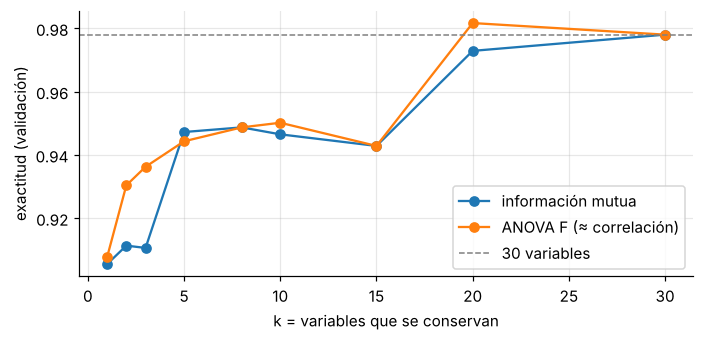

In [12]:
ks = [1, 2, 3, 5, 8, 10, 15, 20, 30]
curvas = {}
for nombre, score in [("información mutua", mi_clasif), ("ANOVA F (≈ correlación)", f_classif)]:
    curvas[nombre] = []
    for k in ks:
        pipe = Pipeline([("sc", StandardScaler()), ("sel", SelectKBest(score, k=k)), ("lr", LogisticRegression(max_iter=3000))])
        curvas[nombre].append(evalua(pipe)[0])

tabla_k = pd.DataFrame(curvas, index=ks).round(3); tabla_k.index.name = "k"
print(tabla_k.T.to_string())
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for nombre, vals in curvas.items():
    ax.plot(ks, vals, marker="o", label=nombre)
ax.axhline(acc0, color="gray", ls="--", lw=1, label="30 variables")
ax.set_xlabel("k = variables que se conservan"); ax.set_ylabel("exactitud (validación)"); ax.legend(); plt.tight_layout(); plt.show()

✏️ **Pregunta 3.4.** ¿Con cuántas variables ($k$) un filtro iguala a la línea base? ¿Cómo elegirías $k$ de forma honesta? ¿Por qué es importante que `SelectKBest`
esté **dentro** del `Pipeline` y no antes de la validación cruzada?

> ✅ **Respuesta (solucionario)**
>
> **Cuántas variables:** con $k\approx 20$ los filtros igualan la línea base (información mutua 0.973, ANOVA F 0.982, contra 0.978). Con $k$ entre 5 y 15 se quedan en 0.943–0.950, y con 1–3 variables, en 0.91–0.94. Diferencias menores a ≈0.01 están dentro del ruido.
>
> **Cómo elegir $k$ honestamente:** tratándolo como un **hiperparámetro**: se compara por validación cruzada **dentro del entrenamiento** (por ejemplo, `GridSearchCV` sobre `sel__k`) y el conjunto de prueba se usa una sola vez al final. Nunca se elige $k$ viendo el resultado en la prueba.
>
> **Por qué dentro del `Pipeline`:** la selección usa las etiquetas. Si se hace antes de la validación cruzada, las filas de validación ya participaron en elegir las variables y la exactitud sale inflada (la Parte 8 lo muestra con ruido puro: 0.833 contra 0.450). Dentro del pipeline, en cada partición se vuelve a elegir con el pedazo de entrenamiento.

## Parte 4 — Envoltura: eliminación recursiva de variables (RFE)  *(presentación D1–D5)*

RFE entrena el modelo, quita la variable con menor |coeficiente|, y repite. Se usa sobre variables **estandarizadas** para que los coeficientes sean comparables.
Usaremos `Xs_train` (el entrenamiento ya estandarizado, definido en la Parte 3).

In [13]:
rfe = RFE(LogisticRegression(max_iter=3000), n_features_to_select=10, step=1).fit(Xs_train, y_train)
vars_rfe10 = list(X_train.columns[rfe.support_])
print("RFE con k = 10 elige:")
print(vars_rfe10)

# Orden de eliminación completo: RFE hasta dejar una sola variable (ranking 1 = la que sobrevive hasta el final)
orden = pd.Series(RFE(LogisticRegression(max_iter=3000), n_features_to_select=1, step=1).fit(Xs_train, y_train).ranking_,
                  index=X_train.columns).sort_values()
print("\nÚltimas en sobrevivir :", list(orden.index[:5]))
print("Primeras en eliminarse:", list(orden.index[-5:][::-1]))

RFE con k = 10 elige:
['mean area', 'radius error', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst concavity', 'worst concave points']

Últimas en sobrevivir : ['worst area', 'worst concave points', 'worst radius', 'radius error', 'worst texture']
Primeras en eliminarse: ['worst compactness', 'concavity error', 'smoothness error', 'mean symmetry', 'worst fractal dimension']


Número óptimo de variables según RFECV: 22 (exactitud 0.976)
   con  1 variables: 0.919
   con  3 variables: 0.943
   con  5 variables: 0.958
   con  8 variables: 0.958
   con 10 variables: 0.971
   con 15 variables: 0.971
   con 30 variables: 0.974


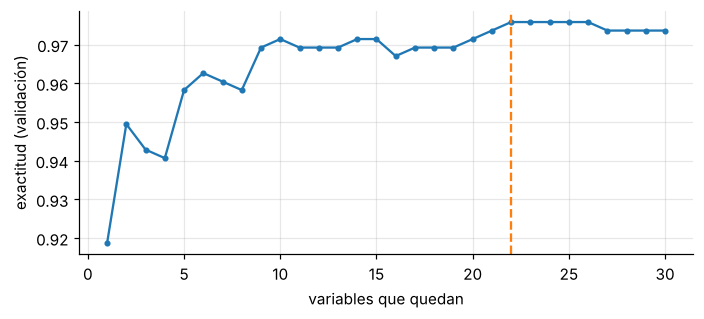

In [14]:
# RFECV: la validación cruzada decide cuántas variables conservar
rfecv = RFECV(LogisticRegression(max_iter=3000), step=1, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="accuracy").fit(Xs_train, y_train)
curva = rfecv.cv_results_["mean_test_score"]
print("Número óptimo de variables según RFECV:", rfecv.n_features_, f"(exactitud {curva.max():.3f})")
for k in [1, 3, 5, 8, 10, 15, 30]:
    print(f"   con {k:2d} variables: {curva[k - 1]:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3.0))
ax.plot(range(1, 31), curva, marker="o", ms=3)
ax.axvline(rfecv.n_features_, color="C1", ls="--"); ax.set_xlabel("variables que quedan"); ax.set_ylabel("exactitud (validación)")
plt.tight_layout(); plt.show()

✏️ **Pregunta 4.1.** (a) ¿Qué tipo de variables sobreviven hasta el final y cuáles se eliminan primero? ¿Hay medidas de textura entre las que sobreviven?
(b) ¿Cuántas variables recomienda RFECV y cuántas elegirías tú viendo la curva? (c) ¿Por qué RFE reentrena en cada ronda en lugar de ordenar una sola vez?

> ✅ **Respuesta (solucionario)**
>
> **(a)** Sobreviven hasta el final `worst area`, `worst concave points`, `worst radius`, `radius error` y `worst texture`: **tamaño** (área y radio), **irregularidad del contorno** (puntos cóncavos) y **textura**. Se eliminan primero `worst compactness`, `concavity error`, `smoothness error`, `mean symmetry` y `worst fractal dimension`: medidas de suavidad, simetría, fractalidad y errores estándar. Sí: `worst texture` sobrevive, y es una dimensión distinta del tamaño, por eso RFE no repite «lo mismo» como lo hace un filtro por correlación.
>
> **(b)** RFECV recomienda **22** variables (exactitud 0.976), pero la curva es casi plana: con 10 variables es 0.971, con 15 también 0.971, con 30, 0.974 y con 5, 0.958. Yo elegiría **10**: pierde ≈0.3–0.5 puntos y usa un tercio de las variables.
>
> **(c)** Cuando se quita una variable, las demás **cambian de importancia**, sobre todo las correlacionadas (radio, perímetro, área): al quitar una de ellas, las otras heredan parte de su peso. Si se ordenara una sola vez, se podrían eliminar juntas variables que se compartían la información, o conservarse todas; la recursión recalcula el modelo en cada ronda.

## Parte 5 — Integrado: selección con Lasso  *(presentación E1–E5)*

La regresión logística con penalización L1 lleva coeficientes a cero. El parámetro `C` $=1/\alpha$ controla la fuerza:
**menor C, más penalización**. Trazamos la trayectoria completa y elegimos `C` por validación cruzada.

Mejor C por validación: 0.151 -> 9 variables con coeficiente distinto de cero, exactitud 0.976
   C =   0.005:  0 variables activas, exactitud 0.374
   C =   0.024:  4 variables activas, exactitud 0.938
   C =   0.116:  8 variables activas, exactitud 0.974
   C =   0.560: 13 variables activas, exactitud 0.974
   C =   2.698: 19 variables activas, exactitud 0.967


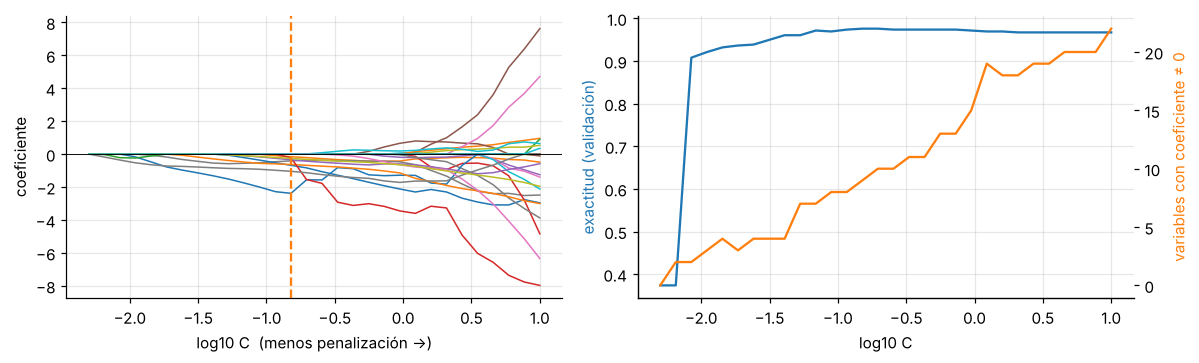

In [15]:
Cs = np.logspace(-2.3, 1.0, 30)
coefs, nz, accs = [], [], []
for C_ in Cs:
    m = LogisticRegression(penalty="l1", solver="liblinear", random_state=0, C=C_, max_iter=5000).fit(Xs_train, y_train)
    coefs.append(m.coef_[0]); nz.append(int((m.coef_[0] != 0).sum()))
    accs.append(cross_val_score(LogisticRegression(penalty="l1", solver="liblinear", random_state=0, C=C_, max_iter=5000), Xs_train, y_train,
                                cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean())
coefs = np.array(coefs)
k_best = int(np.argmax(accs))
print(f"Mejor C por validación: {Cs[k_best]:.3f} -> {nz[k_best]} variables con coeficiente distinto de cero, exactitud {accs[k_best]:.3f}")
for i in range(0, 30, 6):
    print(f"   C = {Cs[i]:7.3f}: {nz[i]:2d} variables activas, exactitud {accs[i]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(np.log10(Cs), coefs, lw=1); ax[0].axhline(0, color="k", lw=0.6); ax[0].axvline(np.log10(Cs[k_best]), color="C1", ls="--")
ax[0].set_xlabel("log10 C  (menos penalización →)"); ax[0].set_ylabel("coeficiente")
ax[1].plot(np.log10(Cs), accs, color="C0"); ax[1].set_ylabel("exactitud (validación)", color="C0"); ax[1].set_xlabel("log10 C")
ax2 = ax[1].twinx(); ax2.plot(np.log10(Cs), nz, color="C1"); ax2.set_ylabel("variables con coeficiente ≠ 0", color="C1"); ax2.grid(False)
plt.tight_layout(); plt.show()

In [16]:
# SelectFromModel: se queda con las variables de coeficiente distinto de cero
sfm = SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", random_state=0, C=0.3, max_iter=5000)).fit(Xs_train, y_train)
vars_lasso = list(X_train.columns[sfm.get_support()])
print(f"Lasso con C = 0.3 conserva {len(vars_lasso)} variables:")
print(vars_lasso)
print("\nEn común con RFE (k=10):", sorted(set(vars_lasso) & set(vars_rfe10)))

Lasso con C = 0.3 conserva 11 variables:
['mean texture', 'mean concave points', 'radius error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst area', 'worst smoothness', 'worst concavity', 'worst concave points', 'worst symmetry']

En común con RFE (k=10): ['radius error', 'worst area', 'worst concave points', 'worst concavity', 'worst radius', 'worst smoothness', 'worst texture']


✏️ **Pregunta 5.1.** (a) Describe qué ocurre con los coeficientes cuando disminuye `C`. (b) ¿Cuántas variables activas deja el mejor C y qué pasa con la exactitud si te quedas con solo 4 variables activas?
(c) ¿Qué ocurriría si **no** estandarizaras antes de Lasso? (d) ¿Cuántas variables comparten Lasso y RFE y qué sugiere eso?

> ✅ **Respuesta (solucionario)**
>
> **(a)** Al disminuir `C` crece la penalización y los coeficientes se encogen y llegan a **exactamente 0 uno por uno**: con C = 0.005 no queda ninguna activa, con 0.024 hay 4, con 0.116 hay 8, con 0.56 hay 13 y con 2.7 hay 19. Las variables entran al modelo en orden de importancia.
>
> **(b)** El mejor C por validación (0.151) deja **9 variables** con exactitud 0.976. Entre 8 y 13 variables activas la exactitud casi no cambia (0.974); con 4 variables baja a 0.938 (≈ 4 puntos menos). Con ≈ 8 variables basta. Con todos los coeficientes en cero el modelo es una constante (el intercepto también queda penalizado en `liblinear`): predice «maligno» para todos y acierta 0.374, la proporción de malignos.
>
> **(c)** La penalización L1 trata igual a todos los coeficientes, así que una variable con unidades pequeñas (suavidad ≈ 0.1) necesita un coeficiente grande para pesar lo mismo y es **castigada más**: saldría por su escala, no por inútil, mientras que las de área (≈ 10³) sobrevivirían con coeficientes diminutos. Por eso siempre se estandariza primero, dentro del `Pipeline`.
>
> **(d)** Comparten 7 variables (`radius error`, `worst area`, `worst concave points`, `worst concavity`, `worst radius`, `worst smoothness`, `worst texture`) de las 10–11 que elige cada uno. Eso sugiere que ese núcleo es robusto al método; las diferencias están en variables correlacionadas entre sí (RFE conserva `mean area` y `area error`; Lasso, `mean concave points` y `mean texture`).

## Parte 6 — Comparación de los cuatro métodos con el mismo protocolo  *(presentación F1, F4)*

Ahora ponemos los cuatro métodos en igualdad de condiciones: **StandardScaler → selector → regresión logística**, con la selección **dentro**
del `Pipeline` (se rehace en cada partición). Para cada método y número de variables $k$ medimos exactitud **y** sensibilidad a casos malignos.

In [17]:
def lr(): return LogisticRegression(max_iter=3000)

METODOS = ["Filtro: información mutua", "Filtro: ANOVA F", "Envoltura: RFE", "Integrado: Lasso"]


def selector(metodo, k):
    if metodo == "Filtro: información mutua":
        return SelectKBest(mi_clasif, k=k)
    if metodo == "Filtro: ANOVA F":
        return SelectKBest(f_classif, k=k)
    if metodo == "Envoltura: RFE":
        return RFE(lr(), n_features_to_select=k, step=1)
    if metodo == "Integrado: Lasso":      # max_features=k y threshold=-inf: se queda con las k de mayor |coeficiente|
        return SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", random_state=0, C=0.3, max_iter=5000), max_features=k, threshold=-np.inf)


ks = [3, 5, 8, 10, 15, 20, 30]
filas = []
for metodo in METODOS:
    for k in ks:
        pipe = Pipeline([("sc", StandardScaler()), ("sel", selector(metodo, k)), ("lr", lr())])
        a, s = evalua(pipe)
        filas.append({"método": metodo, "k": k, "exactitud": a, "sensibilidad": s})
res = pd.DataFrame(filas)
print("Exactitud de validación (línea base con 30 variables: %.3f)" % acc0)
print(res.pivot(index="método", columns="k", values="exactitud").round(3).to_string())
print("\nSensibilidad a malignos (línea base: %.3f)" % sens0)
print(res.pivot(index="método", columns="k", values="sensibilidad").round(3).to_string())

Exactitud de validación (línea base con 30 variables: 0.978)
k                             3      5      8      10     15     20     30
método                                                                    
Envoltura: RFE             0.945  0.965  0.962  0.968  0.972  0.977  0.978
Filtro: ANOVA F            0.936  0.944  0.949  0.950  0.943  0.982  0.978
Filtro: información mutua  0.911  0.947  0.949  0.947  0.943  0.973  0.978
Integrado: Lasso           0.933  0.966  0.973  0.973  0.978  0.977  0.978

Sensibilidad a malignos (línea base: 0.961)
k                             3      5      8      10     15     20     30
método                                                                    
Envoltura: RFE             0.924  0.953  0.943  0.945  0.953  0.957  0.961
Filtro: ANOVA F            0.900  0.914  0.920  0.927  0.927  0.965  0.961
Filtro: información mutua  0.851  0.918  0.924  0.925  0.927  0.955  0.961
Integrado: Lasso           0.904  0.949  0.953  0.959  0.963  0.963  

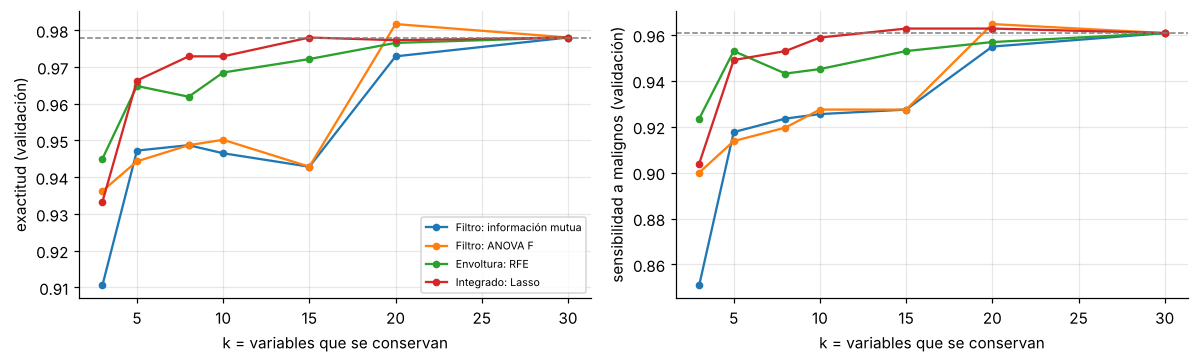

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for metodo in METODOS:
    d = res[res["método"] == metodo]
    ax[0].plot(d["k"], d["exactitud"], marker="o", ms=4, label=metodo)
    ax[1].plot(d["k"], d["sensibilidad"], marker="o", ms=4, label=metodo)
ax[0].axhline(acc0, color="gray", ls="--", lw=1); ax[1].axhline(sens0, color="gray", ls="--", lw=1)
ax[0].set_ylabel("exactitud (validación)"); ax[1].set_ylabel("sensibilidad a malignos (validación)")
for a_ in ax: a_.set_xlabel("k = variables que se conservan")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

✏️ **Pregunta 6.1.** (a) Con pocas variables ($k$ entre 5 y 10), ¿qué métodos rinden mejor y qué tienen en común sus listas? (b) ¿A partir de qué $k$ se igualan todos con la línea base y por qué?
(c) ¿Cambia la conclusión si miras la sensibilidad en vez de la exactitud?

> ✅ **Respuesta (solucionario)**
>
> **(a)** Con $k$ entre 5 y 10 rinden mejor **Lasso** (0.966, 0.973, 0.973) y **RFE** (0.965, 0.962, 0.968) que los filtros (0.944–0.950). Los dos filtros eligen **la misma lista** con $k=8$: radio, perímetro y área (medios y peores) y puntos cóncavos; es decir, 6 de 8 son medidas de tamaño del mismo núcleo, información repetida. RFE y Lasso incluyen variables que se **complementan** (`worst texture`, `worst smoothness`, `radius error`).
>
> **(b)** Todos se igualan a la línea base (0.978) hacia $k\approx15$–20 (Lasso 0.978 con 15; RFE 0.977 con 20; filtros 0.973–0.982 con 20) y son idénticos con $k=30$ porque ya usan las mismas 30 variables. Después de 15–20 variables, el resto añade información redundante.
>
> **(c)** La conclusión se mantiene y se acentúa: con $k=10$ la sensibilidad es 0.959 (Lasso), 0.945 (RFE) y 0.925–0.927 (filtros), contra 0.961 de la línea base. Los filtros dejan escapar ≈ 3 malignos más por cada 100 que Lasso. Con pocas variables la sensibilidad cae más que la exactitud, y es la métrica que importa clínicamente.

**¿Qué variables elige cada método?** Ajustamos cada uno con $k=8$ sobre todo el entrenamiento y listamos las elegidas.
Luego armas la **tabla entregable**.

In [19]:
K_TABLA = 8
elegidas = {}
for metodo in METODOS:
    sel = selector(metodo, K_TABLA).fit(Xs_train, y_train)
    elegidas[metodo] = list(X_train.columns[sel.get_support()])
    print(f"{metodo:26s}", elegidas[metodo])

# Comentarios para cada fila (✏️ escribe el tuyo en el alumno)
comentarios = {
    "Línea base (30 variables)": "Referencia: las 30 variables dan la mejor exactitud y sensibilidad, pero es la menos interpretable.",
    "Filtro: información mutua": "Elige tamaño (radio, perímetro, área) y puntos cóncavos: 6 de 8 son medidas de tamaño redundantes. Estable y barato, pero rinde menos con pocas variables.",
    "Filtro: ANOVA F": "Misma lista que la información mutua con 8 variables: no aporta nada distinto y repite información.",
    "Envoltura: RFE": "Mezcla tamaño, textura y suavidad, que se complementan: mejor que los filtros con 8 variables. Más costo de cómputo y menos estable.",
    "Integrado: Lasso": "El mejor equilibrio con 8 variables (0.973 / 0.953). Depende de C y de estandarizar, y su lista cambia más entre remuestras.",
}

Filtro: información mutua  ['mean radius', 'mean perimeter', 'mean area', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concave points']
Filtro: ANOVA F            ['mean radius', 'mean perimeter', 'mean area', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concave points']
Envoltura: RFE             ['radius error', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst concave points']
Integrado: Lasso           ['mean concave points', 'radius error', 'worst radius', 'worst texture', 'worst area', 'worst smoothness', 'worst concave points', 'worst symmetry']


In [20]:
filas = [{"método": "Línea base (30 variables)", "k": 30, "exactitud_cv": round(acc0, 3), "sensibilidad_cv": round(sens0, 3),
          "variables": "todas", "comentario": comentarios["Línea base (30 variables)"]}]
for metodo in METODOS:
    f_ = res[(res["método"] == metodo) & (res["k"] == K_TABLA)].iloc[0]
    filas.append({"método": metodo, "k": K_TABLA, "exactitud_cv": round(f_["exactitud"], 3), "sensibilidad_cv": round(f_["sensibilidad"], 3),
                  "variables": "; ".join(elegidas[metodo]), "comentario": comentarios[metodo]})
entregable = pd.DataFrame(filas)
entregable.to_csv("entregable_unidad3.csv", index=False)
entregable[["método", "k", "exactitud_cv", "sensibilidad_cv", "comentario"]]

,método,k,exactitud_cv,sensibilidad_cv,comentario
0,Línea base (30 variables),30,0.978,0.961,Referencia: las 30 variables dan la mejor exac...
1,Filtro: información mutua,8,0.949,0.924,"Elige tamaño (radio, perímetro, área) y puntos..."
2,Filtro: ANOVA F,8,0.949,0.920,Misma lista que la información mutua con 8 var...
3,Envoltura: RFE,8,0.962,0.943,"Mezcla tamaño, textura y suavidad, que se comp..."
4,Integrado: Lasso,8,0.973,0.953,El mejor equilibrio con 8 variables (0.973 / 0...


### Elegir un modelo y usar el conjunto de prueba **una sola vez**

Con lo que viste, elige un método y un $k$ (la regla: el modelo más **pequeño** cuya validación quede cerca de la mejor). Ajústalo con todo el entrenamiento
y evalúalo en el conjunto de prueba, junto con la línea base.

In [21]:
metodo_elegido, k_elegido = "Integrado: Lasso", 10
final = Pipeline([("sc", StandardScaler()), ("sel", selector(metodo_elegido, k_elegido)), ("lr", lr())]).fit(X_train, y_train)
baseline = make_pipeline(StandardScaler(), lr()).fit(X_train, y_train)

for nombre, mod in [("Línea base (30)", baseline), (f"{metodo_elegido}, k={k_elegido}", final)]:
    pred = mod.predict(X_test)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    print(f"{nombre:28s} exactitud en prueba = {accuracy_score(y_test, pred):.3f}   sensibilidad a malignos = {recall_score(y_test, pred, pos_label=0):.3f}"
          f"   (malignos perdidos: {cm[0, 1]} de {cm[0].sum()}; benignos con falsa alarma: {cm[1, 0]} de {cm[1].sum()})")
print("\nVariables del modelo final:", list(X_train.columns[final[:-1].named_steps['sel'].get_support()]))

Línea base (30)              exactitud en prueba = 0.982   sensibilidad a malignos = 0.976   (malignos perdidos: 1 de 42; benignos con falsa alarma: 1 de 72)
Integrado: Lasso, k=10       exactitud en prueba = 0.982   sensibilidad a malignos = 0.976   (malignos perdidos: 1 de 42; benignos con falsa alarma: 1 de 72)

Variables del modelo final: ['mean texture', 'mean concave points', 'radius error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst area', 'worst smoothness', 'worst concave points', 'worst symmetry']


✏️ **Pregunta 6.2.** ¿Qué método y $k$ elegiste y por qué? ¿Se parece la exactitud en prueba a la de validación? Con solo 114 pacientes en prueba, ¿cuánta
diferencia entre dos modelos te parecería real? ¿Un paciente menos o más detectado cambia mucho la sensibilidad?

> ✅ **Respuesta (solucionario)**
>
> *(Ejemplo; cada estudiante puede justificar una elección distinta.)* **Lasso con $k=10$**: es el método de mayor exactitud y sensibilidad con 10 variables (0.973 y 0.959), prácticamente igual que la línea base con 30 (0.978 y 0.961), con un tercio de las variables.
>
> **Prueba:** exactitud 0.982 y sensibilidad 0.976 (1 maligno perdido de 42; 1 falsa alarma de 72), **idéntico a la línea base**. La prueba salió un poco mejor que la validación (0.973 / 0.959), lo cual es normal por azar.
>
> **Cuánta diferencia es real:** con 114 pacientes, uno solo equivale a 0.9 puntos de exactitud y a **2.4 puntos de sensibilidad** (1/42). Diferencias de uno o dos pacientes son ruido; por eso las decisiones se toman con la validación cruzada repetida (que usa 455 pacientes 15 veces) y la prueba solo confirma que no hubo sorpresas.

## Parte 7 — Estabilidad de la selección  *(presentación F2)*

Una lista de «variables importantes» que cambia con cada muestra no sirve para explicar nada. Repetimos la selección de $k=5$ variables
con **30 remuestras bootstrap** del entrenamiento y contamos con qué frecuencia se elige cada variable.

In [22]:
B, k5 = 30, 5
rng = np.random.default_rng(0)
freq = {m: pd.Series(0.0, index=X_train.columns) for m in METODOS}
for b in range(B):
    idx = rng.choice(len(X_train), len(X_train), replace=True)
    Xb, yb = X_train.iloc[idx], y_train.iloc[idx]
    Xbs = pd.DataFrame(StandardScaler().fit_transform(Xb), columns=X_train.columns)
    for m in METODOS:
        freq[m][X_train.columns[selector(m, k5).fit(Xbs, yb).get_support()]] += 1 / B
F = pd.DataFrame(freq)
tabla_est = F.loc[F.max(axis=1).sort_values(ascending=False).index[:12]].round(2)
print(tabla_est.to_string())
resumen = pd.DataFrame({"frecuencia media de las 5 más elegidas": [np.sort(F[m].values)[::-1][:k5].mean() for m in METODOS],
                        "variables distintas que alguna vez se eligieron": [int((F[m] > 0).sum()) for m in METODOS]}, index=METODOS)
print(); print(resumen.round(2).to_string())

                      Filtro: información mutua  Filtro: ANOVA F  Envoltura: RFE  Integrado: Lasso
worst concave points                       0.87             1.00            0.97              0.90
worst radius                               0.97             1.00            1.00              0.67
worst perimeter                            1.00             1.00            0.40              0.10
worst area                                 1.00             0.23            0.83              0.67
mean concave points                        0.93             0.90            0.07              0.47
mean perimeter                             0.23             0.80            0.03              0.00
radius error                               0.00             0.00            0.50              0.63
worst texture                              0.00             0.00            0.60              0.53
worst smoothness                           0.00             0.00            0.13              0.47
area error

✏️ **Pregunta 7.1.** ¿Qué métodos son más estables y cuáles reparten su elección entre muchas variables? ¿Por qué ocurre eso con RFE y Lasso en estos datos?
Si tuvieras que **explicarle a un médico** qué variables importan, ¿cómo usarías esta tabla?

> ✅ **Respuesta (solucionario)**
>
> **Estables:** los filtros. Las 5 variables más elegidas tienen frecuencia media de 0.95 (información mutua) y 0.94 (ANOVA), y en total solo se eligieron 6 y 7 variables distintas. Pero son **siempre la misma familia redundante** (`worst perimeter`, `worst area`, `worst radius`, `mean concave points`...).
>
> **Menos estables:** RFE (0.78, 12 variables distintas) y Lasso (0.68, 13). Con variables correlacionadas (radio, perímetro y área se reparten la misma información, r ≈ 0.99), cualquiera sirve y cuál queda depende casi del azar de la muestra; Lasso elige una del grupo y deja a las otras en 0.
>
> **Con un médico:** no presentaría «las 5 variables importantes», sino **grupos**: *tamaño del núcleo* (radio, perímetro, área), *irregularidad del contorno* (`worst concave points`, elegida con frecuencia 0.87–1.00 por los cuatro métodos) y *textura*. Usaría las frecuencias como medida de confianza y le pediría que valide que esos grupos tienen sentido biológico.

## Parte 8 — Una fuga de datos al seleccionar  *(presentación C9)*

Seleccionar variables usa las etiquetas. Lo comprobamos con un caso en el que **no hay nada que aprender**: 60 filas, 1 000 variables de ruido puro y etiquetas al azar.
Un modelo honesto debe acertar cerca de 0.50.

In [23]:
rng = np.random.default_rng(0)
Xr = rng.normal(size=(60, 1000)); yr = rng.integers(0, 2, 60)
cv_r = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)

# MAL: elegir las 10 «mejores» con TODAS las etiquetas y después validar
Xsel = SelectKBest(f_classif, k=10).fit_transform(Xr, yr)
mal = cross_val_score(LogisticRegression(), Xsel, yr, cv=cv_r).mean()

# BIEN: el selector es un paso del Pipeline (se rehace en cada partición)
pipe_bien = Pipeline([("sel", SelectKBest(f_classif, k=10)), ("lr", LogisticRegression())])
bien = cross_val_score(pipe_bien, Xr, yr, cv=cv_r).mean()
print(f"Selección ANTES de validar (fuga): exactitud = {mal:.3f}")
print(f"Selección DENTRO del pipeline    : exactitud = {bien:.3f}   (azar = 0.50)")

Selección ANTES de validar (fuga): exactitud = 0.833
Selección DENTRO del pipeline    : exactitud = 0.450   (azar = 0.50)


✏️ **Pregunta 8.1.** ¿Por qué la selección fuera de la validación da una exactitud tan alta con datos que son puro ruido? ¿Cuál de las dos cifras es creíble?
¿Qué otras operaciones de esta unidad tendrían el mismo problema si se hicieran antes de dividir?

> ✅ **Respuesta (solucionario)**
>
> **Por qué sale alto:** la selección usa las etiquetas. Con 1 000 variables de ruido y 60 filas, algunas variables se correlacionan con las etiquetas **por casualidad**; al elegir las 10 «mejores» con todas las etiquetas, las filas de validación ya participaron en la elección, y el modelo parece predecirlas (0.833) aunque no hay nada que aprender.
>
> **La cifra creíble:** la del selector **dentro del pipeline**, 0.450 (≈ azar, 0.50; por debajo por ruido): en cada partición la selección solo ve las filas de entrenamiento.
>
> **Otras operaciones con el mismo riesgo:** todo lo que *aprende de los datos o de las etiquetas*: RFE, Lasso/`SelectFromModel`, `SelectKBest`, la poda por correlación con el objetivo, el escalado (con efecto mucho menor), la imputación, y también **elegir $k$ o $C$ viendo la prueba**. Las variables de dominio sin parámetros aprendidos (razones, $\log$) no tienen este problema.

## Parte 9 — Recomendación final

✏️ **Pregunta 9.1.** Redacta una recomendación breve (6 a 8 líneas) para el equipo médico: qué método y cuántas variables propones, con qué exactitud y sensibilidad esperada
(**validación**, no prueba), qué variables componen el modelo, qué cuidados tomaste para no engañarte (fuga, estabilidad) y qué validación necesitarías de un experto antes de usarlo.

> ✅ **Respuesta (solucionario)**
>
> *(Ejemplo.)* **Recomendación:** regresión logística con **10 variables elegidas por Lasso** (`C=0.3`, variables estandarizadas), dentro de un `Pipeline` donde el selector se rehace en cada partición.
>
> **Desempeño esperado:** exactitud de validación **0.973** y sensibilidad a malignos **0.959** (5×3 particiones), casi igual que con las 30 variables (0.978 y 0.961). En la prueba, usada una sola vez: 0.982 y 0.976 (1 maligno perdido de 42).
>
> **Variables:** `mean texture`, `mean concave points`, `radius error`, `fractal dimension error`, `worst radius`, `worst texture`, `worst area`, `worst smoothness`, `worst concave points`, `worst symmetry`. Cubren tamaño, irregularidad y textura.
>
> **Cuidados:** selección dentro de la validación cruzada (la fuga con ruido da 0.83 contra 0.45); `k` elegido en validación; estabilidad revisada: las variables de tamaño se intercambian, así que se interpretan **por grupos**, no una a una.
>
> **Antes de usarlo:** un patólogo debe validar que las variables tengan sentido biológico; hace falta validación externa con otros hospitales y equipos; se debe fijar con el equipo médico el umbral de decisión (la sensibilidad pesa más que la exactitud) y el modelo debe apoyar, no reemplazar, el diagnóstico.

---
**Reto opcional.** Agrega `ElasticNet` a la comparación (`LogisticRegression(penalty="elasticnet", solver="saga", random_state=0, l1_ratio=0.5)` dentro de `SelectFromModel`)
y compara su lista de variables con la de Lasso con $k=8$. ¿Qué esperarías para variables correlacionadas?

In [24]:
# Reto opcional
def selector_en(k):
    return SelectFromModel(LogisticRegression(penalty="elasticnet", solver="saga", random_state=0, l1_ratio=0.5, C=0.3, max_iter=5000),
                           max_features=k, threshold=-np.inf)

pipe_en = Pipeline([("sc", StandardScaler()), ("sel", selector_en(8)), ("lr", lr())])
a, s = evalua(pipe_en)
print(f"Elastic Net (l1_ratio=0.5), k=8: exactitud = {a:.3f}   sensibilidad = {s:.3f}")
sel_en = selector_en(8).fit(Xs_train, y_train)
print("Variables:", list(X_train.columns[sel_en.get_support()]))

Elastic Net (l1_ratio=0.5), k=8: exactitud = 0.971   sensibilidad = 0.953
Variables: ['mean concave points', 'radius error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst concave points']


> ✅ **Respuesta (solucionario)**
>
> **Resultado:** con $k=8$, Elastic Net (`l1_ratio=0.5`) obtiene exactitud ≈ 0.971 y sensibilidad ≈ 0.953, igual que Lasso con $k=8$ (0.973 y 0.953). Elige `mean concave points`, `radius error`, `worst radius`, `worst texture`, `worst perimeter`, `worst area`, `worst smoothness` y `worst concave points`: casi la misma lista que Lasso, pero con `worst perimeter` en lugar de `worst symmetry`.
>
> **Qué esperar:** con variables correlacionadas, Elastic Net tiende a **repartir** el peso entre todas las del grupo (efecto de agrupamiento) en vez de elegir una al azar como Lasso; por eso `worst radius`, `worst perimeter` y `worst area` entran juntas. Su lista suele ser **más estable** entre remuestras, a costa de conservar variables redundantes. Para comprobarlo habría que repetir el experimento de estabilidad de la Parte 7.